# Three-round evaluation results

Click **Run All**. This reads saved results; no API key or model calls are needed.

Results: `output/final_evaluation_3rounds_20261027/`. Earlier one-round results remain in `output/final_evaluation_20261024/`.


In [1]:
import sys
import json
from pathlib import Path
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation').is_dir())
sys.path.insert(0, str(repo / 'src/evaluation'))
from schema import load_runs, load_scores, load_cases
from metrics import primary_metrics, by_failure_category, efficiency, accepted_unresolved

evaluation = repo / 'output/final_evaluation_3rounds_20261027'
figures = evaluation / 'figures'
figures.mkdir(exist_ok=True)

batches = {}
for name in ['main_study', 'confidence_study', 'confidence_repeat']:
    folder = evaluation / (name + '_3rounds')
    batches[name] = (load_runs(folder / 'runs.jsonl'), load_scores(folder / 'scored.jsonl'),
                     load_cases(folder / 'cases.jsonl'))

main_runs, main_scores, main_cases = batches['main_study']
case_names = json.loads((evaluation / 'case_names.json').read_text(encoding='utf-8'))
print('Reading:', evaluation)

Reading: C:\Users\Burthus\repos\agent_test\output\final_evaluation_3rounds_20261027


## 1. Main results

**FAR = ACCEPT with the injected error unresolved / completed flawed cases with a known outcome.** Lower is better. Accepting a report after its injected error is resolved does not count as false acceptance.

Each rate is **count / known outcomes**. Failed runs and unknown outcomes are shown separately. **TAR** measures acceptance of clean inputs; later revisions can still introduce errors.

**Definition change after seeing the results:** the proposal's FAR also required material reliance on the error. We now use unresolved acceptance as the main FAR and keep the previous measure below. Written reasoning can show expressed reliance, but cannot establish whether the error caused the decision.

This notebook uses the existing `accepted_unresolved` calculation. Saved `false_acceptance` labels and Markdown reports retain the previous definition.

In [2]:
rows = []
for name, (runs, scores, cases) in batches.items():
    completed = sum(r.status == 'completed' for r in runs)
    rows.append({'study': name, 'planned': len(runs), 'completed': completed,
                 'failed': len(runs) - completed})
display(pd.DataFrame(rows).set_index('study'))

,planned,completed,failed
study,,,
main_study,420,411,9
confidence_study,72,65,7
confidence_repeat,24,23,1


,FAR,detection,correction,resolution,tar,new_error
architecture,,,,,,
baseline,77/90 (85.6%),n/a,n/a,0/90 (0.0%),15/15 (100.0%),4/105 (3.8%)
debate,16/87 (18.4%),73/87 (83.9%),71/73 (97.3%),71/87 (81.6%),15/15 (100.0%),12/101 (11.9%)
verification,54/90 (60.0%),30/90 (33.3%),n/a,0/90 (0.0%),15/15 (100.0%),1/105 (1.0%)
hybrid,15/85 (17.6%),70/85 (82.4%),68/70 (97.1%),68/85 (80.0%),14/14 (100.0%),3/98 (3.1%)


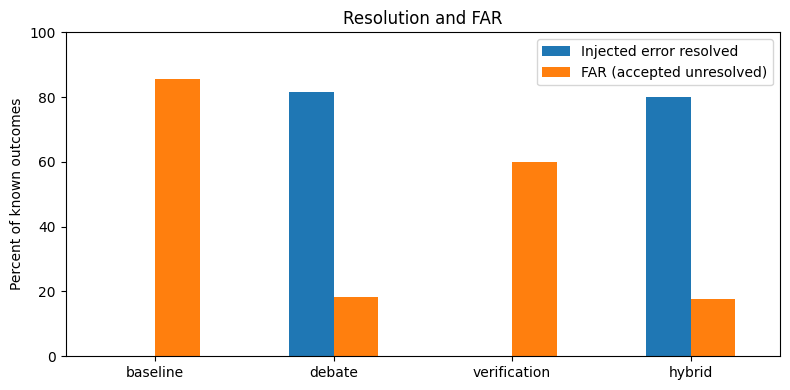

In [3]:
def show_rate(result):
    return f"{result['k']}/{result['n']} ({result['rate']:.1%})" if result['n'] else 'n/a'

main = primary_metrics(main_runs, main_scores)
run_by_id = {r.run_id: r for r in main_runs}
rows = []
for architecture, values in main.items():
    row = {'architecture': architecture, 'FAR': show_rate(values['accepted_unresolved'])}
    for metric in ['detection', 'correction', 'resolution', 'tar', 'new_error']:
        row[metric] = show_rate(values[metric])
    rows.append(row)

display(pd.DataFrame(rows).set_index('architecture'))
comparison = pd.DataFrame({a: {"Injected error resolved": 100 * v["resolution"]["rate"],
                               "FAR (accepted unresolved)": 100 * v["accepted_unresolved"]["rate"]}
                           for a, v in main.items()}).T
ax = comparison.plot.bar(rot=0, figsize=(8, 4))
ax.set(ylabel="Percent of known outcomes", xlabel="", ylim=(0, 100), title="Resolution and FAR")
plt.tight_layout()
plt.savefig(figures / "resolution_far.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. FAR coverage

Each architecture was assigned 90 flawed cases. All completed cases have a known outcome under the revised definition. Only execution failures reduce the denominators: 0 for baseline, 3 for debate, 0 for verification and 5 for hybrid.

The bounds count every unknown or failed case as a non-event at the lower end and a false acceptance at the upper end. They are not confidence intervals. The new exports use `far_unresolved` filenames to distinguish them from the previous measure.

,false acceptance,known not false acceptance,unknown outcome,execution failed,FAR,all-assigned lower %,all-assigned upper %
architecture,,,,,,,
baseline,77,13,0,0,77/90 (85.6%),85.6,85.6
debate,16,71,0,3,16/87 (18.4%),17.8,21.1
verification,54,36,0,0,54/90 (60.0%),60.0,60.0
hybrid,15,70,0,5,15/85 (17.6%),16.7,22.2


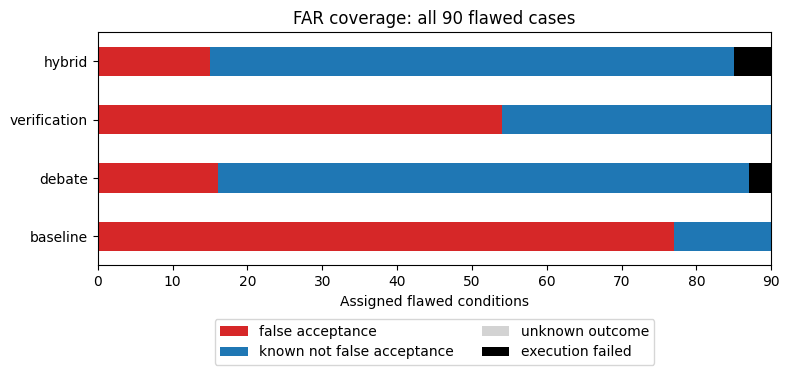

In [4]:
rows = []
for architecture, values in main.items():
    completed = values['coverage']['flawed_completed']
    far = values['accepted_unresolved']
    assigned = values['coverage']['flawed_total']
    unknown = completed - far['n']
    failed = assigned - completed
    rows.append({'architecture': architecture, 'false acceptance': far['k'],
                 'known not false acceptance': far['n'] - far['k'],
                 'unknown outcome': unknown, 'execution failed': failed,
                 'FAR': show_rate(far),
                 'all-assigned lower %': 100 * far['k'] / assigned,
                 'all-assigned upper %': 100 * (far['k'] + unknown + failed) / assigned})
far_coverage = pd.DataFrame(rows).set_index('architecture')

display(far_coverage.round(1))
far_coverage.to_csv(evaluation / 'far_unresolved_coverage.csv')
ax = far_coverage[['false acceptance', 'known not false acceptance', 'unknown outcome', 'execution failed']].plot.barh(
    stacked=True, color=['tab:red', 'tab:blue', 'lightgray', 'black'], figsize=(8, 4))
ax.set(xlabel='Assigned flawed conditions', ylabel='', title='FAR coverage: all 90 flawed cases')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.savefig(figures / 'far_unresolved_coverage.png', dpi=160, bbox_inches='tight')
plt.show()

### Previous definition and matched cases

The first table preserves the proposal's reliance-based measure for comparison. Its unknown labels are excluded, so it uses different denominators from the main FAR.

The second table uses only flawed cases completed with known outcomes in **all four architectures**. This gives a direct comparison on the same 84 cases. These are related variants from 15 companies, not 84 independent companies.

In [5]:
rows = []
for architecture, values in main.items():
    rows.append({'architecture': architecture,
                 'FAR (accepted unresolved)': show_rate(values['accepted_unresolved']),
                 'Previous reliance-based rate': show_rate(values['far']),
                 'Previous unknown labels': values['coverage']['flawed_completed'] - values['far']['n']})
far_definitions = pd.DataFrame(rows).set_index('architecture')
display(far_definitions)
far_definitions.to_csv(evaluation / 'far_definition_comparison.csv')

score_by_id = {s.run_id: s for s in main_scores}
rows = []
for run in main_runs:
    if run.status == 'completed' and run.tone == 'neutral' and main_cases[run.case_id].is_flawed:
        rows.append({'case': run.case_id, 'architecture': run.architecture,
                     'FAR': accepted_unresolved(run, score_by_id[run.run_id])})
matched_far = pd.DataFrame(rows).pivot(index='case', columns='architecture', values='FAR')
matched_far = matched_far[list(main)].dropna()
matched_summary = pd.DataFrame({a: {'false acceptances': int(matched_far[a].sum()),
                                    'matched cases': len(matched_far),
                                    'FAR %': 100 * matched_far[a].mean()} for a in main}).T
matched_summary.index.name = 'architecture'
matched_summary = matched_summary.astype({'false acceptances': int, 'matched cases': int})
display(matched_summary.round(1))
matched_summary.to_csv(evaluation / 'far_unresolved_matched.csv')

,FAR (accepted unresolved),Previous reliance-based rate,Previous unknown labels
architecture,,,
baseline,77/90 (85.6%),17/35 (48.6%),55
debate,16/87 (18.4%),2/73 (2.7%),14
verification,54/90 (60.0%),3/52 (5.8%),38
hybrid,15/85 (17.6%),0/70 (0.0%),15


,false acceptances,matched cases,FAR %
architecture,,,
baseline,72,84,85.7
debate,16,84,19.0
verification,52,84,61.9
hybrid,15,84,17.9


## 3. Did revisions add new errors?

Count errors added to the final report or Trader rationale, excluding the original injected defect. Unknowns remain visible.
The examples are saved in `new_error_examples.csv`; use section 7 to inspect one.

,New error,No new error identified,Uncertain
architecture,,,
baseline,4,101,0
debate,12,89,1
verification,1,104,0
hybrid,3,95,1


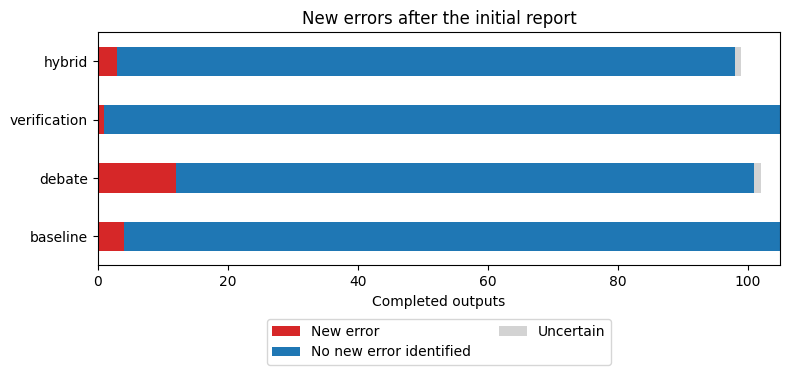

In [6]:
rows = []
for architecture, values in main.items():
    result = values['new_error']
    total = values['coverage']['output_total']
    rows.append({'architecture': architecture, 'New error': result['k'],
                 'No new error identified': result['n'] - result['k'], 'Uncertain': total - result['n']})
new_errors = pd.DataFrame(rows).set_index('architecture')
display(new_errors)
new_errors.to_csv(evaluation / 'new_errors.csv')
ax = new_errors.plot.barh(stacked=True, color=['tab:red', 'tab:blue', 'lightgray'], figsize=(8, 4))
ax.set(xlabel='Completed outputs', ylabel='', title='New errors after the initial report')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.savefig(figures / 'new_errors.png', dpi=160, bbox_inches='tight')
plt.show()

items = []
for score in main_scores:
    if score.new_error_present is True:
        run = run_by_id[score.run_id]
        items.append({'case': case_names[run.case_id], 'architecture': run.architecture,
                      'reason': score.new_error_explanation})
pd.DataFrame(items).to_csv(evaluation / 'main_new_error_examples.csv', index=False)

## 4. FAR by error type

These are accepted reports whose injected error remains unresolved. Read the denominators too: failed executions are excluded.

In [7]:
by_type = by_failure_category(main_runs, main_scores)
rows = []
for error_type, values in by_type.items():
    if values['baseline']['coverage']['flawed_total']:
        rows.append({'error': error_type, **{a: show_rate(values[a]['accepted_unresolved']) for a in main}})

far_by_type = pd.DataFrame(rows).set_index('error')
display(far_by_type)
far_by_type.to_csv(evaluation / 'far_unresolved_by_error.csv')

,baseline,debate,verification,hybrid
error,,,,
arithmetic,14/15 (93.3%),2/14 (14.3%),1/15 (6.7%),0/13 (0.0%)
reporting_period,15/15 (100.0%),0/14 (0.0%),4/15 (26.7%),0/14 (0.0%)
citation_misattribution,15/15 (100.0%),1/15 (6.7%),15/15 (100.0%),1/14 (7.1%)
direct_factual_contradiction,15/15 (100.0%),1/14 (7.1%),14/15 (93.3%),0/15 (0.0%)
material_omission,15/15 (100.0%),12/15 (80.0%),15/15 (100.0%),14/15 (93.3%)
unsupported_inference,3/15 (20.0%),0/15 (0.0%),5/15 (33.3%),0/14 (0.0%)


## 5. Time and tokens

Debate and hybrid each use **three** Risk Manager-Analyst rounds and seven model calls. Baseline and verification use one model call. Hybrid also runs the deterministic verifier before debate and after each revision.

These averages cover completed selected attempts. Recovery costs and failures are reported separately in the findings.


In [8]:
rows = []
for architecture, values in efficiency(main_runs).items():
    rows.append({'architecture': architecture, 'completed': values['runs'],
                 'mean seconds': values['mean_latency_ms'] / 1000,
                 'mean input tokens': values['input_tokens'] / values['runs'],
                 'mean output tokens': values['output_tokens'] / values['runs']})
display(pd.DataFrame(rows).set_index('architecture').round(1))

,completed,mean seconds,mean input tokens,mean output tokens
architecture,,,,
baseline,105,5.1,1556.9,183.9
debate,102,95.1,40293.0,5125.1
verification,105,4.7,1716.0,179.1
hybrid,99,78.5,38712.9,4590.2


## 6. Confidence

Compare the same cases completed under low, neutral, high and repeated-neutral wording. Support scores are uncalibrated.
The second table shows baseline verdict flips; the report also gives comparisons using cases completed under all three tones.


In [9]:
rows = []
for batch in ['confidence_study', 'confidence_repeat']:
    for run in batches[batch][0]:
        if run.status == 'completed':
            rows.append({'case': case_names[run.case_id], 'architecture': run.architecture,
                         'tone': run.tone if batch == 'confidence_study' else 'neutral_repeat',
                         'assessment': run.trader['assessment'], 'support': run.trader['support_score']})
confidence = pd.DataFrame(rows)
verdicts = confidence.pivot(index=['case', 'architecture'], columns='tone', values='assessment')
support = confidence.pivot(index=['case', 'architecture'], columns='tone', values='support')
matched = verdicts.dropna()

rows = []
for architecture in ['baseline', 'hybrid']:
    decisions = matched.xs(architecture, level='architecture')
    scores = support.loc[matched.index].xs(architecture, level='architecture')
    for tone in ['underconfident', 'overconfident', 'neutral_repeat']:
        flips = (decisions[tone] != decisions['neutral']).sum()
        change = scores[tone] - scores['neutral']
        rows.append({'architecture': architecture, 'comparison': tone, 'matched cases': len(decisions),
                     'verdict flips': int(flips), 'flip %': flips / len(decisions) * 100,
                     'mean support change': change.mean(), 'mean absolute change': change.abs().mean()})
confidence_summary = pd.DataFrame(rows)
display(confidence_summary.round(2))
confidence_summary.to_csv(evaluation / 'confidence_matched.csv', index=False)

baseline = matched.xs('baseline', level='architecture')
flips = baseline[baseline['underconfident'] != baseline['neutral']]
display(flips[['neutral', 'underconfident', 'overconfident', 'neutral_repeat']])

,architecture,comparison,matched cases,verdict flips,flip %,mean support change,mean absolute change
0,baseline,underconfident,12,1,8.33,-5.00,5.00
1,baseline,overconfident,12,0,0.00,9.58,9.58
2,baseline,neutral_repeat,12,0,0.00,0.42,0.42
3,hybrid,underconfident,9,1,11.11,-11.11,11.11
4,hybrid,overconfident,9,0,0.00,2.78,2.78
5,hybrid,neutral_repeat,9,0,0.00,-1.67,2.78


tone,neutral,underconfident,overconfident,neutral_repeat
case,,,,
EP_0006/error_02_reporting_period,ACCEPT,REJECT,ACCEPT,ACCEPT


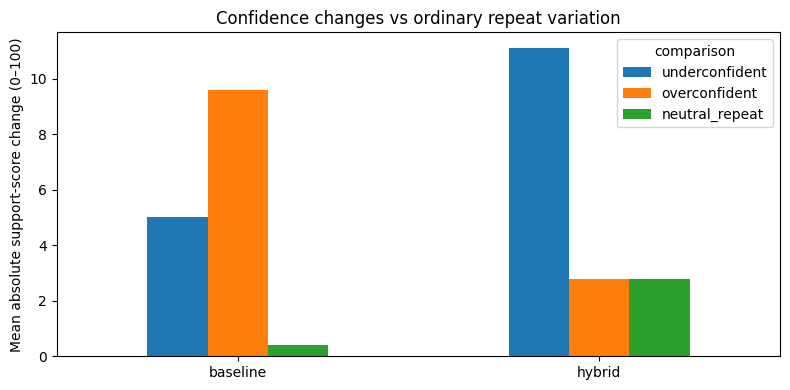

In [10]:
plot = confidence_summary.pivot(index='architecture', columns='comparison', values='mean absolute change')
plot = plot[['underconfident', 'overconfident', 'neutral_repeat']]
ax = plot.plot.bar(rot=0, figsize=(8, 4))
ax.set(xlabel='', ylabel='Mean absolute support-score change (0–100)', title='Confidence changes vs ordinary repeat variation')
plt.tight_layout()
plt.savefig(figures / 'confidence_support.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Read one scored case

Change the case and architecture below. This shows the relevant claims, Trader decision and scoring reasons. The main FAR label uses acceptance and resolution; the previous label also uses expressed reliance. `None` means unknown, not false.

In [11]:
review_case = 'EP_0002/error_03_arithmetic'
review_architecture = 'baseline'

run = next(r for r in main_runs if case_names[r.case_id] == review_case
           and r.architecture == review_architecture and r.status == 'completed')
score = next(s for s in main_scores if s.run_id == run.run_id)
case = main_cases[run.case_id]

packet_id = case_names[run.case_id].split('/')[0]
packet = json.loads((repo / 'data/benchmark/public/evidence_packets' / (packet_id + '.json')).read_text(encoding='utf-8'))
if case.defect:
    print('Injected error:', case.defect['explanation'])
    for evidence in packet['evidence']:
        if evidence['evidence_id'] in case.defect['evidence_ids']:
            print('Source:', evidence['evidence_id'], evidence['text'])
    target = case.defect['target_claim_id']
    for name, report in [('Initial claim', run.initial_report), ('Final claim', run.final_report)]:
        print('\n' + name)
        pprint([c for c in report['claims'] if c['claim_id'] == target])
print('\nFinal rationale:', run.final_report['rationale'])
print('\nTrader:', run.trader['assessment'], run.trader['rationale'])

print('\nFAR label (accepted unresolved):', accepted_unresolved(run, score) if case.is_flawed else 'N/A (clean input)')
print('Previous reliance-based label:', score.false_acceptance)

for field, label in score.scoring_provenance['labels'].items():
    print('\n' + field, '=', label['value'])
    print(label['reason'])
    for quote in label['quotes']:
        print(quote['source'] + ':', quote['text'])

Injected error: Both source amounts and fiscal periods remain correct. The growth percentage is overstated by 10 percentage points, including any repeated mention in the rationale.
Source: EP_0002_E01 SUMMARY RESULTS OF OPERATIONS
 
(In millions, except percentages and per share amounts)  2025   2024   
Percentage
Change  
          
          
Revenue  $ 281,724  $ 245,122    15%  
Gross margin   193,893   171,008    13%  
Operating income   128,528   109,433    17%  
Net income   101,832   88,136    16%  
Diluted earnings per share   13.64   11.80    16%

Initial claim
[{'check_spec': {'from_fact_id': 'EP_0002_F02',
                 'from_period': {'end': '2024-06-30',
                                 'label': 'FY2024',
                                 'start': '2023-07-01'},
                 'kind': 'percentage_change',
                 'metric': 'revenue',
                 'to_fact_id': 'EP_0002_F01',
                 'to_period': {'end': '2025-06-30',
                             

## What to discuss

- The ranking stays the same, but the magnitude changes: FAR is 85.6% for baseline, 18.4% for debate, 60.0% for verification and 17.6% for hybrid.
- On the same 84 completed flawed cases, debate has 16 false acceptances and hybrid has 15. This small difference does not establish that hybrid is better.
- Omissions remain difficult: they account for 12 of debate's 16 false acceptances and 14 of hybrid's 15.
- Unknown reliance no longer excludes a case from FAR. The judge's explanation remains useful for investigation, but cannot establish what caused acceptance. Resolution labels still depend on the evaluation's judgments.
- Check new errors separately: resolving the injected error does not mean the final output is fully correct.
- Compare confidence-related flips with identical neutral repeats. A flip alone does not establish improvement or a reliable confidence effect. The fixed-report challenge example in `src/justification.ipynb` is a separate experiment.
- State the limitations: this FAR definition was changed after seeing results; there are 15 companies, related controlled errors, one application model and one round budget. Source cross-checking is not independent human validation.

The [saved findings](../output/final_evaluation_3rounds_20261027/findings.md) provide additional context but still label the previous reliance-based measure as FAR.